# exp 11 logic regression and K-NN

In [11]:
import pandas as pd
from pandas import read_csv
from matplotlib import pyplot

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [14]:
#url="http://github.com/jbrownlee/Datasets/master/iris.csv"
path=url="C:\\Users\\Priya Rani\\Documents\\iris.csv"
names=["sepal_length","sepal_width","petal_length","petal_width","class"]
dataset=pd.read_csv(path,names=names)
print(dataset)

     sepal_length  sepal_width  petal_length  petal_width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


In [5]:
url='http://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'

In [6]:
import pandas as pd
attributes=["sepal_length","sepal_width","petal_length","petal_width","class"]
dataset=pd.read_csv(url,names=attributes)
dataset.columns=attributes
print(dataset)

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split

path = "C:\\Users\\Priya Rani\\Documents\\iris.csv"
names = ["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
dataset = pd.read_csv(path, names=names)

# Split the data set into training, testing and validation
array = dataset.values
X = array[:, 0:4]
y = array[:, 4]

# This line will now run perfectly
X_train, X_validation, Y_train, Y_validation = train_test_split(X, y, test_size=0.20, random_state=1, shuffle=True)

print("Data successfully split!")

Data successfully split!


In [17]:
models=[]
models.append(('LR',LogisticRegression(solver='liblinear')))
models.append(('KNN',KNeighborsClassifier()))
print(models)
result=[]
names=[]
for name,model in models:
    kfold=StratifiedKFold(n_splits=10,random_state=1,shuffle=True)
    cv_result=cross_val_score(model,X_train,Y_train,cv=kfold,scoring="accuracy")
    result.append(cv_result)
    names.append(name)
    print("%s:%f(%f)" %(name,cv_result.mean(),cv_result.std()))
pyplot.boxplot(result,label=names)
pyplot.title('algorithm comparison')
pyplot.show()

[('LR', LogisticRegression(solver='liblinear')), ('KNN', KNeighborsClassifier())]


ValueError: 
All the 10 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Priya Rani\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py", line 860, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Priya Rani\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\Priya Rani\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1466, in fit
    raise ValueError(
    ...<4 lines>...
    )
ValueError: The 'liblinear' 

In [38]:
X=[10,20,30,40,50,60]
Y=[30,12,34,32,65,50]
# Find for 34,20
# Give K=2
# k-nn
for i in X:
    print(i)
for j in Y:
    print(j)

10
20
30
40
50
60
30
12
34
32
65
50


In [13]:
import math

X = [10, 20, 30, 40, 50, 60]
Y = [30, 12, 34, 32, 65, 50]

# Target point
tx = 34
ty = 20

distances = []


for i in range(len(X)):
    d = math.sqrt((X[i] - tx)**2 + (Y[i] - ty)**2)
    distances.append((d, X[i], Y[i]))


distances.sort()

# K = 2
K = 2

print("Nearest 2 points:")

for i in range(K):
    print("Point:", (distances[i][1], distances[i][2]),
          "Distance:", round(distances[i][0], 2))

Nearest 2 points:
Point: (40, 32) Distance: 13.42
Point: (30, 34) Distance: 14.56


In [14]:
import math

X = [10, 20, 30, 40, 50, 60]
Y = [30, 12, 34, 32, 65, 50]

# Target point
x = 34
y = 20

for i in range(len(X)):
    d = math.sqrt((X[i] - x)**2 + (Y[i] - y)**2)
    print((X[i], Y[i]), "=", round(d, 2))

(10, 30) = 26.0
(20, 12) = 16.12
(30, 34) = 14.56
(40, 32) = 13.42
(50, 65) = 47.76
(60, 50) = 39.7


LR: 0.938406 (0.030892)
KNN: 0.922995 (0.031829)


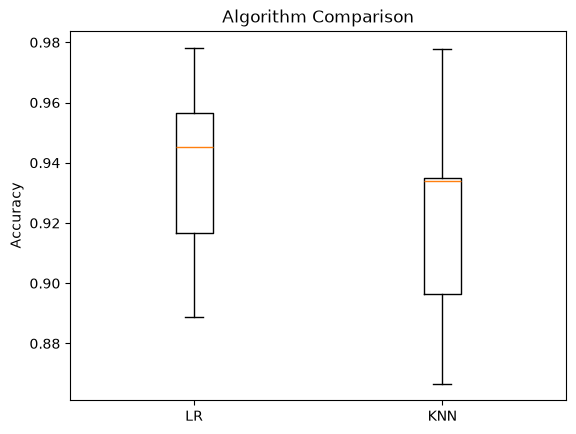

In [2]:

# Import libraries
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from matplotlib import pyplot

# Load dataset
data = load_breast_cancer()
X = data.data
Y = data.target

# Split dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1, stratify=Y
)

# Create models
models = []
models.append(('LR', LogisticRegression(solver='liblinear', max_iter=1000)))
models.append(('KNN', KNeighborsClassifier()))

# Store results
results = []
names = []

# 10-fold cross-validation
kfold = StratifiedKFold(
    n_splits=10, random_state=1, shuffle=True
)

for name, model in models:
    cv_result = cross_val_score(
        model, X_train, Y_train,
        cv=kfold, scoring='accuracy'
    )

    results.append(cv_result)
    names.append(name)

    print("%s: %f (%f)" %
          (name, cv_result.mean(), cv_result.std()))

# Compare algorithms using boxplot
pyplot.boxplot(results, tick_labels=names)
pyplot.title('Algorithm Comparison')
pyplot.ylabel('Accuracy')
pyplot.show()

